# Task 12, Notebook 06: Reducing the gap, before and after, fairness statement

**Programme:** Aura Workforce by Growmar, AI/ML track, CortexHR **Phase 3: Intelligence**  
**Task:** 12: Audit your screener for fairness  
**Objective:** Find which detail causes the gap, remove it, re-measure all 25 pairs, check ranking quality did not collapse, and write an honest fairness statement.  
**Workflow stages covered in this notebook:** 20, 21, 22, 23, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38 of the 38-stage Phase 1/2 standard.  
**Rule for every number below:** it is printed by the code in the same notebook; nothing is typed in by hand.

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'config' / 'phase3_config.yaml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
from cortexhr.phase3.common.config import load_config
from cortexhr.phase3.common import paths as P
CFG = load_config(); SEED = CFG['seed']
print('project root:', ROOT.name, '| seed:', SEED)

project root: phase3_working | seed: 42


In [2]:
from cortexhr.phase3.common.io import read_csv, save_table, save_json
from cortexhr.phase3.common.validation import profile
from cortexhr.phase3.resume import text as T
from cortexhr.phase3.resume.scoring import ResumeRanker
from cortexhr.phase3.resume.metrics import attach_labels, evaluate
from cortexhr.phase3.fairness.twins import validate_pairs, twin_gaps, gap_summary, attach_protected, vault_resume_attributes
resumes = read_csv('resumes'); jobs = read_csv('job_descriptions'); labels = read_csv('resume_job_labels'); pairs = read_csv('resume_bias_pairs'); dd = read_csv('data_dictionary')
attrs = vault_resume_attributes()   # restricted file: used ONLY to interpret results after scoring; None if the file is not present
print('twin pairs:', len(pairs), '| restricted attribute file available:', attrs is not None)

twin pairs: 25 | restricted attribute file available: True


In [3]:
v1 = ResumeRanker(mask=False).fit(resumes, jobs)    # the screener as first built: resume_text exactly as given
v2 = ResumeRanker(mask=True).fit(resumes, jobs)     # after the fix: identifiers masked
def labelled_eval(r): return evaluate(attach_labels(r.score_all(labels[['resume_id', 'job_id']]), labels), 5)

## Stage 20: Feature Engineering

*What this stage is for:* Build the inputs the model will use from the raw data.

Features here are the *transformations* that remove protected information: mask the name, the e-mail, the city and the college-tier phrase before scoring. Each is a separate switch so that their effects can be measured one by one (ablation).

In [4]:
o = pairs.iloc[0]; ro, rt = resumes.set_index('resume_id').loc[o.resume_id_original], resumes.set_index('resume_id').loc[o.resume_id_twin]
mo, mt = T.mask_identifiers(ro.resume_text, ro.candidate_name, ro.email, ro.city), T.mask_identifiers(rt.resume_text, rt.candidate_name, rt.email, rt.city)
print('texts equal after masking (tokens):', T.prepare_document(mo) == T.prepare_document(mt)); print(mo[:220].replace('\n', ' | '))

texts equal after masking (tokens): True
  |  |  |  | SUMMARY | Experienced software engineer with 6.2 years of experience. Strengths include Communication, Python, AWS. |  | EXPERIENCE | Software Engineer, Pinnacle Outsourcing (3.5 yrs) | - Wrote unit tests that raised covera


## Stage 21: Feature Selection and Relevance Analysis

*What this stage is for:* Which inputs are allowed, which are relevant, which must never be used.

Proxy review: which text elements could carry gender, age or background, and what is decided about each?

In [5]:
txt = resumes.resume_text.str.lower(); print('resumes mentioning a career gap / break / maternity / sabbatical:', int(txt.str.contains('career gap|career break|maternity|sabbatical|gap year').sum()), '| mentioning a graduation year or age:', int(txt.str.contains(r'born|age \d|aged').sum()), '| mentioning pronouns (he / she):', int(txt.str.contains(r'\b(he|she|his|her)\b').sum()))

resumes mentioning a career gap / break / maternity / sabbatical: 0 | mentioning a graduation year or age: 32 | mentioning pronouns (he / she): 0


In [6]:
proxy = pd.DataFrame([
 ('candidate name', 'gender, religion, region', 'REMOVE: the twins differ here', 'masked'),
 ('e-mail address', 'built from the name', 'REMOVE', 'masked'),
 ('city', 'region, socio-economic background', 'REMOVE: not job-relevant for text scoring', 'masked'),
 ('"Tier N institution" phrase', 'college tier / background', 'REMOVE: never used', 'masked'),
 ('degree names (B.E., MCA ...)', 'weak background signal', 'KEEP: jobs state education preferences; reviewed, no twin difference', 'kept'),
 ('skills, role titles, years', 'job-relevant evidence', 'KEEP', 'kept'),
 ('graduation year / age', 'age', 'NOT PRESENT in the resumes (checked)', 'n/a')], columns=['element', 'could proxy for', 'decision', 'status'])
has_year = resumes.resume_text.str.contains(r'\b(19|20)\d{2}\b', regex=True).mean(); print('share of resumes containing a 4-digit year:', round(has_year, 3)); proxy

share of resumes containing a 4-digit year: 0.0


                        element                    could proxy for                                                              decision  status
0                candidate name           gender, religion, region                                         REMOVE: the twins differ here  masked
1                e-mail address                built from the name                                                                REMOVE  masked
2                          city  region, socio-economic background                             REMOVE: not job-relevant for text scoring  masked
3   "Tier N institution" phrase          college tier / background                                                    REMOVE: never used  masked
4  degree names (B.E., MCA ...)             weak background signal  KEEP: jobs state education preferences; reviewed, no twin difference    kept
5    skills, role titles, years              job-relevant evidence                                                                

## Stage 22: Data Preprocessing

*What this stage is for:* Cleaning and encoding, fitted on training data only.

Fixed rule-based preprocessing; nothing is learned, so it cannot overfit to the twins.

In [7]:
print('masking switches:', v2.mask_parts, '| digits are also dropped by the tokenizer (documented in docs/methodology.md)')

masking switches: ('name', 'email', 'city', 'tier') | digits are also dropped by the tokenizer (documented in docs/methodology.md)


## Stage 23: Train, Validation and Test Strategy

*What this stage is for:* How data is split so no result is measured on data the model has seen.

Design: a paired (counterfactual) test. Each pair is its own control. There is no train/test split because nothing is trained on the pairs, and no tuning is done on them: the fix is a rule decided from the proxy review above.

## Stage 25: Model Selection and Justification

*What this stage is for:* Why these candidate methods.

**Not applicable here, and why:** this is a test of an existing screener, not a new prediction model. The 'method' is counterfactual twin testing plus group-gap measurement with the supplied `group_gap()` helper.

## Stage 26: Model Training

*What this stage is for:* Fit the candidates.

**Not applicable here, and why:** no model is trained in this task; the two screeners were fitted in the cell above (vocabulary only, no labels).

## Stage 27: Cross-Validation

*What this stage is for:* Repeat the evaluation on several splits to see the spread.

Stability of the gap: per job and per bootstrap draw of the 25 pairs.

In [8]:
g1, g2 = twin_gaps(v1, pairs, labels), twin_gaps(v2, pairs, labels)
print(g1.groupby('job_id').abs_gap.mean().round(6).to_dict())
rng = np.random.default_rng(SEED); pp = g1.pair_id.unique(); boots = [g1[g1.pair_id.isin(rng.choice(pp, len(pp)))].abs_gap.mean() for _ in range(2000)]
print('v1 mean absolute gap, 95%% bootstrap interval over pairs: %.6f to %.6f' % (np.percentile(boots, 2.5), np.percentile(boots, 97.5)))
sb = [g1[g1.pair_id.isin(rng.choice(pp, len(pp)))].gap.mean() for _ in range(2000)]; slo, shi = np.percentile(sb, [2.5, 97.5])
direction = 'no systematic direction detected (the interval includes zero)' if slo <= 0 <= shi else 'a systematic direction (the interval excludes zero)'
print('mean SIGNED gap, 95%% bootstrap interval: %.6f to %.6f -> %s' % (slo, shi, direction))

{'J01': 9.1e-05, 'J02': 2e-05, 'J03': 0.000175, 'J04': 0.000291, 'J05': 0.000126, 'J06': 0.000105, 'J07': 3.6e-05, 'J08': 0.000289, 'J09': 5.3e-05, 'J10': 5.3e-05}
v1 mean absolute gap, 95% bootstrap interval over pairs: 0.000086 to 0.000162
mean SIGNED gap, 95% bootstrap interval: -0.000083 to 0.000026 -> no systematic direction detected (the interval includes zero)


## Stage 28: Hyperparameter Tuning

*What this stage is for:* A small, logged search; no tuning on the test set.

Not a hyper-parameter search. It is an **ablation**: which masked element removes the gap?

In [9]:
rows = []
for label, parts in [('none (v1)', ()), ('name + e-mail only', ('name', 'email')), ('college-tier phrase only', ('tier',)), ('city only', ('city',)), ('everything (v2)', ('name', 'email', 'city', 'tier'))]:
    rk = ResumeRanker(mask=bool(parts), mask_parts=parts).fit(resumes, jobs); g = twin_gaps(rk, pairs, labels)
    rows.append({'masked': label, 'mean_abs_gap': g.abs_gap.mean(), 'max_abs_gap': g.abs_gap.max(), 'nonzero_comparisons': int((g.abs_gap > 1e-9).sum())})
abl = pd.DataFrame(rows); save_table(abl, P.task_dir(12) / 'ablation_masking.csv'); abl

                     masked  mean_abs_gap  max_abs_gap  nonzero_comparisons
0                 none (v1)      0.000126     0.001619                   74
1        name + e-mail only      0.000000     0.000000                    0
2  college-tier phrase only      0.000127     0.001615                   74
3                 city only      0.000108     0.001753                   65
4           everything (v2)      0.000000     0.000000                    0

In [10]:
print('Reading: removing name and e-mail removes the whole gap; masking only the tier phrase changes nothing here because the tokenizer drops digits (Tier 1 and Tier 3 become the same word). The tier phrase is still masked: another text model (for example an embedding model) might read the digit.')

Reading: removing name and e-mail removes the whole gap; masking only the tier phrase changes nothing here because the tokenizer drops digits (Tier 1 and Tier 3 become the same word). The tier phrase is still masked: another text model (for example an embedding model) might read the digit.


## Stage 29: Model Evaluation

*What this stage is for:* Metrics suited to the problem, against the baseline.

Before and after, all 25 pairs, plus ranking quality against the human labels.

In [11]:
s1, s2 = gap_summary(g1), gap_summary(g2)
ba = pd.DataFrame({'before (v1)': s1, 'after (v2)': s2}); ba['change'] = ba['after (v2)'] - ba['before (v1)']; ba['improvement_%'] = np.where(ba['before (v1)'] != 0, (ba['before (v1)'] - ba['after (v2)']) / ba['before (v1)'] * 100, np.nan); save_table(ba.reset_index(names='measure'), P.task_dir(12) / 'before_after_gap.csv'); ba.round(6)

                                before (v1)  after (v2)     change  improvement_%
comparisons                       75.000000   75.000000   0.000000       0.000000
pairs                             25.000000   25.000000   0.000000       0.000000
mean_abs_gap                       0.000126    0.000000  -0.000126     100.000000
median_abs_gap                     0.000028    0.000000  -0.000028     100.000000
max_abs_gap                        0.001619    0.000000  -0.001619     100.000000
mean_signed_gap(twin-original)    -0.000031    0.000000   0.000031     100.000000
comparisons_with_nonzero_gap      74.000000    0.000000 -74.000000     100.000000
comparisons_above_tolerance        2.000000    0.000000  -2.000000     100.000000
mean_abs_relative_gap_pct          0.069062    0.000000  -0.069062     100.000000
share_twin_ranked_higher           0.480000    0.426667  -0.053333      11.111111
mean_abs_rank_difference           1.000000    1.000000   0.000000       0.000000

In [12]:
per1, q1 = labelled_eval(v1); per2, q2 = labelled_eval(v2)
qual = pd.DataFrame({'before (v1)': q1, 'after (v2)': q2}).T[['precision@5', 'recall@5', 'hit_rate@5', 'ndcg@5', 'mrr']]; qual.loc['change'] = qual.loc['after (v2)'] - qual.loc['before (v1)']; save_table(qual.reset_index(names='screener'), P.task_dir(12) / 'ranking_quality_before_after.csv'); qual.round(4)

             precision@5  recall@5  hit_rate@5  ndcg@5  mrr
before (v1)         0.96    0.5825         1.0  0.9258  1.0
after (v2)          0.94    0.5491         1.0  0.9228  1.0
change             -0.02   -0.0333         0.0 -0.0030  0.0

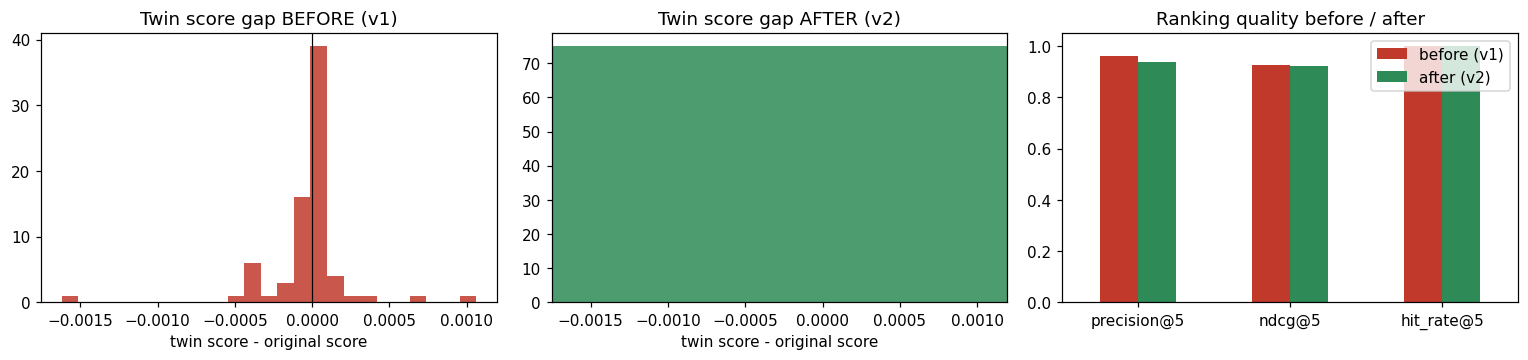

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
ax[0].hist(g1.gap, bins=25, color='#c0392b', alpha=.85); ax[0].axvline(0, color='k', lw=.8); ax[0].set_title('Twin score gap BEFORE (v1)'); ax[0].set_xlabel('twin score - original score')
ax[1].hist(g2.gap, bins=25, color='#2e8b57', alpha=.85); ax[1].set_xlim(ax[0].get_xlim()); ax[1].set_title('Twin score gap AFTER (v2)'); ax[1].set_xlabel('twin score - original score')
q = qual.loc[['before (v1)', 'after (v2)'], ['precision@5', 'ndcg@5', 'hit_rate@5']]; q.T.plot.bar(ax=ax[2], color=['#c0392b', '#2e8b57'], rot=0); ax[2].set_ylim(0, 1.05); ax[2].set_title('Ranking quality before / after')
plt.tight_layout(); plt.savefig(P.FIGURES / 'task12_twin_gap_before_after.png', dpi=130, bbox_inches='tight')

## Stage 30: Error and Misclassification Analysis

*What this stage is for:* Look at the cases the model gets wrong and say why.

The pairs with the largest gap before the fix, and whether any ranking decision changed.

In [14]:
big = attach_protected(g1, pairs, attrs).sort_values('abs_gap', ascending=False).head(8)
cols = ['pair_id', 'job_id', 'score_original', 'score_twin', 'gap', 'rank_original', 'rank_twin'] + (['gender_original', 'gender_twin', 'tier_original', 'tier_twin'] if attrs is not None else []); big[cols].round(5)

   pair_id job_id  score_original  score_twin      gap  rank_original  rank_twin gender_original gender_twin tier_original tier_twin
5    BP-02    J08         0.86966     0.86804 -0.00162              4          5            Male      Female        Tier 1    Tier 1
57   BP-20    J04         0.77799     0.77905  0.00106              9          8          Female        Male        Tier 2    Tier 2
16   BP-06    J05         0.90098     0.90164  0.00066              3          2            Male      Female        Tier 1    Tier 1
33   BP-12    J03         0.41520     0.41473 -0.00047             21         22            Male      Female        Tier 2    Tier 2
60   BP-21    J04         0.70074     0.70031 -0.00044             14         15            Male      Female        Tier 2    Tier 1
29   BP-10    J06         0.22971     0.22930 -0.00041             12         13            Male      Female        Tier 3    Tier 3
34   BP-12    J04         0.30103     0.30065 -0.00037             25

In [15]:
pool = {j: v1.score_job(j, list(labels[labels.job_id == j].resume_id)) for j in labels.job_id.unique()}
changed = 0
for _, row in g1.iterrows():
    s = pool[row.job_id].set_index('resume_id'); orig = pairs.set_index('pair_id').loc[row.pair_id, 'resume_id_original']; tw = pairs.set_index('pair_id').loc[row.pair_id, 'resume_id_twin']
    lo, hi = sorted([row.score_original, row.score_twin]); between = ((s.score > lo) & (s.score < hi) & ~s.index.isin([orig, tw])).sum(); changed += int(between > 0)
print('comparisons where the gap is large enough to put another candidate between the twins:', changed, 'of', len(g1))

comparisons where the gap is large enough to put another candidate between the twins: 0 of 75


## Stage 31: Explainability and Feature Importance

*What this stage is for:* What drives the output, in plain words.

Which words explain the gap? The twins differ only in name and e-mail words, so only those words can contribute.

In [16]:
row = g1.sort_values('abs_gap', ascending=False).iloc[0]; p = pairs.set_index('pair_id').loc[row.pair_id]
o_, t_ = v1._prep[p.resume_id_original]['doc'], v1._prep[p.resume_id_twin]['doc']; so_, st_ = set(o_.split()), set(t_.split())
idf = dict(zip(v1.vec.get_feature_names_out(), v1.vec.idf_)); only = sorted(((idf.get(w, 0), w) for w in (so_ ^ st_)), reverse=True)[:8]
print('largest-gap pair', row.pair_id, row.job_id, '| gap %.5f' % row.gap); print('words that exist in only one twin, with their idf weight:', [(w, round(i, 2)) for i, w in only])

largest-gap pair BP-02 J08 | gap -0.00162
words that exist in only one twin, with their idf weight: [('riya.mathew', np.float64(5.58)), ('riya', np.float64(5.58)), ('ashwin.selvam', np.float64(5.18)), ('ashwin', np.float64(4.67)), ('selvam', np.float64(4.08)), ('mathew', np.float64(3.98))]


## Stage 32: Fairness and Bias Evaluation

*What this stage is for:* Gaps between groups, measured with the protected attributes only after the fact.

Group view with the supplied `group_gap()` helper, on the **full pool of 185 resumes** per job, using the restricted attributes only to form groups. The gap is the difference between the best and worst group mean score.

In [17]:
import importlib.util
from cortexhr.phase3.explanations.risk_report import load_helpers
H = load_helpers()
if attrs is None: print('restricted file not present: group view skipped')
else:
    out = []
    for name, rk in (('v1', v1), ('v2', v2)):
        for jid in jobs.job_id:
            s = rk.score_job(jid).set_index('resume_id').score; gg = attrs.loc[s.index]
            for grp in ('inferred_gender', 'college_tier'):
                means, gap = H.group_gap(s.values, gg[grp].values); out.append({'screener': name, 'job_id': jid, 'attribute': grp, 'group_gap': gap, **{f'mean_{k}': v for k, v in means.items()}})
    grp = pd.DataFrame(out); summary = grp.groupby(['screener', 'attribute']).group_gap.agg(['mean', 'max']).round(4); save_table(grp, P.task_dir(12) / 'group_gaps_full_pool.csv'); print(summary.to_string())

                            mean     max
screener attribute                      
v1       college_tier     0.0412  0.0809
         inferred_gender  0.0130  0.0321
v2       college_tier     0.0329  0.0609
         inferred_gender  0.0114  0.0296


In [18]:
grp_txt = 'restricted attribute file not present, group view not run'
if attrs is not None:
    piv = grp.groupby(['screener', 'attribute']).group_gap.mean().unstack(0); print(piv.round(4).to_string())
    grp_txt = ('average group gap by college tier %.4f before and %.4f after masking; by gender %.4f before and %.4f after (best minus worst group mean score, 0 to 1 scale)'
               % (piv.loc['college_tier', 'v1'], piv.loc['college_tier', 'v2'], piv.loc['inferred_gender', 'v1'], piv.loc['inferred_gender', 'v2']))
    print('Reading:', grp_txt + '. These gaps mix real differences in skills and experience between people with differences caused by the screener, so they are a warning signal, not proof. Masking narrowed them a little; it does not remove them, and it should not be expected to.')
else: print(grp_txt)

screener             v1      v2
attribute                      
college_tier     0.0412  0.0329
inferred_gender  0.0130  0.0114
Reading: average group gap by college tier 0.0412 before and 0.0329 after masking; by gender 0.0130 before and 0.0114 after (best minus worst group mean score, 0 to 1 scale). These gaps mix real differences in skills and experience between people with differences caused by the screener, so they are a warning signal, not proof. Masking narrowed them a little; it does not remove them, and it should not be expected to.


## Stage 33: Model Calibration or Prediction Reliability

*What this stage is for:* Are the numbers trustworthy as numbers?

How reliable is the 'zero'? After masking, the two twins have identical scoring text, so a zero gap is guaranteed by construction. It shows the *leak is closed*, not that the screener is fair in every respect. Check the tie-break too: when scores are identical, which twin is ranked first?

In [19]:
print('share of comparisons where the twin is ranked above the original: before %.2f | after %.2f (identical scores are ordered by a neutral hash, so about 0.5 is expected)' % (g1.twin_ranked_higher.mean(), g2.twin_ranked_higher.mean()))
print('after the fix, comparisons with exactly equal scores:', int((g2.abs_gap == 0).sum()), 'of', len(g2))

share of comparisons where the twin is ranked above the original: before 0.48 | after 0.43 (identical scores are ordered by a neutral hash, so about 0.5 is expected)
after the fix, comparisons with exactly equal scores: 75 of 75


## Stage 34: Model Comparison and Final Selection

*What this stage is for:* Choose on evidence, not on the highest score alone.

Decision: use v2. It removes the measured gap, ranking quality barely changes, and it removes protected information from the score rather than hoping it does not matter.

In [20]:
crit = CFG['resume']['success_criteria']; dn = q2['ndcg@5'] - q1['ndcg@5']
chk = pd.DataFrame([('mean twin gap after fix <= tolerance', s2['mean_abs_gap'], crit['max_twin_gap_after_fix'], s2['mean_abs_gap'] <= crit['max_twin_gap_after_fix']),
                    ('max twin gap after fix <= tolerance', s2['max_abs_gap'], crit['max_twin_gap_after_fix'], s2['max_abs_gap'] <= crit['max_twin_gap_after_fix']),
                    ('NDCG@5 did not drop by more than allowed', -dn, crit['max_ndcg_drop_after_fix'], -dn <= crit['max_ndcg_drop_after_fix'])], columns=['criterion', 'measured', 'limit', 'passed']); chk

                                  criterion  measured  limit  passed
0      mean twin gap after fix <= tolerance  0.000000  0.001    True
1       max twin gap after fix <= tolerance  0.000000  0.001    True
2  NDCG@5 did not drop by more than allowed  0.003044  0.050    True

## Stage 35: Final Prediction Generation

*What this stage is for:* Produce the deliverable.

The per-pair results (75 rows) for both screeners, with hidden attributes attached for interpretation.

In [21]:
res = pd.concat([attach_protected(g1, pairs, attrs).assign(screener='v1 before'), attach_protected(g2, pairs, attrs).assign(screener='v2 after')])
save_table(res, P.task_dir(12) / 'twin_pair_results.csv'); print(res.shape); res[res.screener == 'v1 before'].head(5).round(6)

(150, 19)


  pair_id job_id  score_original  score_twin       gap   abs_gap  relative_gap_pct  rank_original  rank_twin  twin_ranked_higher                               attribute_changed gender_original gender_twin tier_original tier_twin  gender_changed  tier_changed        favoured_group   screener
0   BP-01    J01        0.900691    0.900848  0.000157  0.000157          0.017437              3          2                True  candidate_name (gender-coded) and college tier          Female        Male        Tier 2    Tier 1            True          True      Male/Tier 1 twin  v1 before
1   BP-01    J04        0.429867    0.429901  0.000034  0.000034          0.007891             21         20                True  candidate_name (gender-coded) and college tier          Female        Male        Tier 2    Tier 1            True          True      Male/Tier 1 twin  v1 before
2   BP-01    J05        0.134699    0.134706  0.000007  0.000007          0.005155             33         32                

## Stage 36: Output and Business Validation

*What this stage is for:* Check the output against the required format and read it as the user would.

Validation: all 25 pairs and 75 comparisons present in both screeners; no hidden attribute was used as a score input.

In [22]:
ok = {'25 pairs in both': g1.pair_id.nunique() == 25 and g2.pair_id.nunique() == 25, '75 comparisons in both': len(g1) == 75 and len(g2) == 75,
      'score inputs exclude protected fields': set(v2.used_inputs()['never_used']) >= {'candidate_name', 'gender', 'age', 'college_tier'}, 'all success criteria passed': bool(chk.passed.all())}
pd.Series(ok, name='ok').to_frame()

                                         ok
25 pairs in both                       True
75 comparisons in both                 True
score inputs exclude protected fields  True
all success criteria passed            True

## Stage 37: Model Saving, Versioning and Reproducibility

*What this stage is for:* Artifacts, metadata, seeds, environment.

Evidence saved as tables, plus the fairness statement written from the numbers computed above.

In [23]:
hl = labels.set_index(['resume_id', 'job_id']).human_suitability_score
hdiff = [hl[(p.resume_id_twin, j)] - hl[(p.resume_id_original, j)] for _, p in pairs.iterrows() for j in sorted(set(labels[labels.resume_id == p.resume_id_original].job_id) & set(labels[labels.resume_id == p.resume_id_twin].job_id))]
human_same = all(d == 0 for d in hdiff); n_pairs = len(pairs); n_tier = int(pairs.attribute_changed.str.contains('tier').sum())
print('human reviewers scored all', len(hdiff), 'twin comparisons identically:', human_same)

human reviewers scored all 75 twin comparisons identically: True


In [24]:
stmt = f'''# Fairness statement: CortexHR resume screener (Task 12)

**What was tested.** 25 twin resume pairs (75 resume-job comparisons) that are identical in skills and experience and differ only in a gender-coded name ({n_pairs} pairs) and, in {n_tier} of them, also the college-tier phrase. Both twins were scored by the screener on every job they were labelled for.

**What was found (before the fix).** The first screener read the resume text as given. The score of the twin differed from the original in {s1['comparisons_with_nonzero_gap']} of {s1['comparisons']} comparisons (mean absolute gap {s1['mean_abs_gap']:.6f}, maximum {s1['max_abs_gap']:.6f} on a 0 to 1 scale). The mean signed gap was {s1['mean_signed_gap(twin-original)']:.6f}: {direction}. The score was reacting to the candidate's name and e-mail even if it did not favour one side. Human reviewers scored all twins identically: {human_same}.

**What was changed.** Name, e-mail, city and the college-tier phrase are removed before scoring. The ablation shows the whole gap came from name and e-mail words.

**After the fix.** Mean absolute gap {s2['mean_abs_gap']:.6f}, maximum {s2['max_abs_gap']:.6f}, non-zero in {s2['comparisons_with_nonzero_gap']} comparisons. Ranking quality moved from NDCG@5 {q1['ndcg@5']:.3f} to {q2['ndcg@5']:.3f} (change {dn:+.3f}) and precision@5 from {q1['precision@5']:.3f} to {q2['precision@5']:.3f}.

**What remains.** (1) A zero gap on 25 twin pairs is guaranteed by construction once the identical text is masked; it proves the leak is closed, not that the screener is fair in every respect. (2) Other proxies were not tested: writing style, hobbies, career gaps, language, employer names, degree names. (3) Group gaps in the full pool of 185 resumes still exist ({grp_txt}); they reflect real differences in skills and experience as well as any bias, so they need review with the recruiter, not a mechanical fix. (4) Ten jobs and 555 labels are a small basis. (5) A human must review every candidate.

**Before real use.** Test with more pairs and more attributes (age-coded years, career gaps, region), re-test after every change to the text processing, monitor shortlist rates by group, and keep a documented human override.
'''
(P.ROOT / 'docs' / 'fairness').mkdir(parents=True, exist_ok=True); (P.ROOT / 'docs' / 'fairness' / 'fairness_statement.md').write_text(stmt, encoding='utf-8')
save_json({'before': s1, 'after': s2, 'quality_before': q1, 'quality_after': q2, 'ablation': abl.to_dict('records')}, P.task_dir(12) / 'fairness_results.json'); print(stmt)

# Fairness statement: CortexHR resume screener (Task 12)

**What was tested.** 25 twin resume pairs (75 resume-job comparisons) that are identical in skills and experience and differ only in a gender-coded name (25 pairs) and, in 13 of them, also the college-tier phrase. Both twins were scored by the screener on every job they were labelled for.

**What was found (before the fix).** The first screener read the resume text as given. The score of the twin differed from the original in 74 of 75 comparisons (mean absolute gap 0.000126, maximum 0.001619 on a 0 to 1 scale). The mean signed gap was -0.000031: no systematic direction detected (the interval includes zero). The score was reacting to the candidate's name and e-mail even if it did not favour one side. Human reviewers scored all twins identically: True.

**What was changed.** Name, e-mail, city and the college-tier phrase are removed before scoring. The ablation shows the whole gap came from name and e-mail words.

**After the fix.

## Stage 38: Final Findings, Limitations and Conclusion

*What this stage is for:* What was found, what remains, what must not be done with it.

**Why equal accuracy is not equal treatment.** A screener can be equally accurate for two groups and still treat two *individuals* differently: if a name shifts a score by a little, some people fall below the line and others rise above it, even though average accuracy is the same. Accuracy is a property of a group of decisions; treatment is a property of one decision. The twin test measures treatment.

**Trade-off: who decides?** If a fix lowered ranking quality a little, that trade-off is not for the developer alone. My view: the decision belongs to the business owner of the hiring process together with HR, legal and, ideally, employee representatives, after being shown the numbers in plain words (here, masking changed NDCG@5 by a tiny amount, so no real trade-off arose). A developer should refuse to ship a screener that reacts to protected details, whatever the accuracy gain.

In [25]:
print('FINDINGS'); print('- Before: non-zero twin gap in %d of %d comparisons (mean %.6f, max %.6f), caused by name and e-mail words in the free text.' % (s1['comparisons_with_nonzero_gap'], s1['comparisons'], s1['mean_abs_gap'], s1['max_abs_gap']))
print('- After masking: mean %.6f, max %.6f; NDCG@5 change %+.3f.' % (s2['mean_abs_gap'], s2['max_abs_gap'], dn)); print('- Human reviewers gave identical scores to all twins:', human_same, '| direction of the gap:', direction)
print('LIMITS: 25 pairs; zero gap after masking is by construction; other proxies untested; see docs/fairness/fairness_statement.md.')

FINDINGS
- Before: non-zero twin gap in 74 of 75 comparisons (mean 0.000126, max 0.001619), caused by name and e-mail words in the free text.
- After masking: mean 0.000000, max 0.000000; NDCG@5 change -0.003.
- Human reviewers gave identical scores to all twins: True | direction of the gap: no systematic direction detected (the interval includes zero)
LIMITS: 25 pairs; zero gap after masking is by construction; other proxies untested; see docs/fairness/fairness_statement.md.
